In [1]:
import pandas as pd
import numpy as np
from collections import Counter
import matplotlib.pyplot as plt
from torch.utils.data import Dataset, DataLoader

print("Everything works!")

Everything works!


In [2]:
def read_conll(filepath):
    sentences = []
    tags = []
    current_sentence = []
    current_tags = []
# Read Cell format file and convert it into a list of sentences and corresponding tags
    with open(filepath, "r", encoding="utf-8") as f:

        for line in f:

            line = line.strip()

            # sentence ended
            if line == "": # if reach to the end of a sentence store the current sentence and tags into the list of sentences and tags
                if current_sentence:
                    sentences.append(current_sentence)
                    tags.append(current_tags)

                    current_sentence = []
                    current_tags = []
                continue

            cols = line.split("\t") # divide the line into columns based on tab separation and store as list

            word = cols[1] # get the word from
            cpos = cols[3] # get the coarse POS tag from
            fpos = cols[4] # get the fine POS tag from

            joint_tag = f"{cpos}-{fpos}" # combine the coarse and fine POS tags into a single tag

            current_sentence.append(word)
            current_tags.append(joint_tag)

    return sentences, tags

In [3]:
train_sentences, train_tags = read_conll( # train sentences and tags from the training dataset
    "en-universal-train.conll"
)

dev_sentences, dev_tags = read_conll(
    "en-universal-dev.conll"
)

In [4]:
print(train_sentences[0])
print()
print(train_tags[0])

['In', 'an', 'Oct.', '19', 'review', 'of', '``', 'The', 'Misanthrope', "''", 'at', 'Chicago', "'s", 'Goodman', 'Theatre', '(', '``', 'Revitalized', 'Classics', 'Take', 'the', 'Stage', 'in', 'Windy', 'City', ',', "''", 'Leisure', '&', 'Arts', ')', ',', 'the', 'role', 'of', 'Celimene', ',', 'played', 'by', 'Kim', 'Cattrall', ',', 'was', 'mistakenly', 'attributed', 'to', 'Christina', 'Haag', '.']

['ADP-IN', 'DET-DT', 'NOUN-NNP', 'NUM-CD', 'NOUN-NN', 'ADP-IN', '.-``', 'DET-DT', 'NOUN-NN', ".-''", 'ADP-IN', 'NOUN-NNP', 'PRT-POS', 'NOUN-NNP', 'NOUN-NNP', '.-(', '.-``', 'VERB-VBN', 'NOUN-NNS', 'VERB-VBP', 'DET-DT', 'NOUN-NN', 'ADP-IN', 'NOUN-NNP', 'NOUN-NNP', '.-,', ".-''", 'NOUN-NN', 'CONJ-CC', 'NOUN-NNS', '.-)', '.-,', 'DET-DT', 'NOUN-NN', 'ADP-IN', 'NOUN-NNP', '.-,', 'VERB-VBN', 'ADP-IN', 'NOUN-NNP', 'NOUN-NNP', '.-,', 'VERB-VBD', 'ADV-RB', 'VERB-VBN', 'ADP-IN', 'NOUN-NNP', 'NOUN-NNP', '.-.']


In [5]:
num_sentences = len(train_sentences)

num_words = sum(
    len(sentence)
    for sentence in train_sentences
)

avg_length = np.mean(
    [len(sentence)
     for sentence in train_sentences]
)

print("Number of sentences:", num_sentences)
print("Number of words:", num_words)
print("Average sentence length:", avg_length)

Number of sentences: 37840
Number of words: 902902
Average sentence length: 23.861046511627908


In [6]:
lengths = [
    len(sentence)
    for sentence in train_sentences
]
# extract the lengths of all sentences in the training dataset and store them in a list
print("Longest sentence:", max(lengths))
print("Shortest sentence:", min(lengths))

Longest sentence: 141
Shortest sentence: 1


In [8]:
all_tags = []
# compile a list of all tags in the training dataset by iterating through each sentence's tags and extending the all_tags list with them 
# compute the frequency of each tag in the training dataset using the Counter class from the collections module
for sentence_tags in train_tags:
    all_tags.extend(sentence_tags)

tag_counter = Counter(all_tags)

print("Number of unique tags:",
      len(tag_counter))

print()

print("Top 20 tags:")

for tag, count in tag_counter.most_common(20):
    print(tag, count)

Number of unique tags: 45

Top 20 tags:
NOUN-NN 126176
ADP-IN 102515
NOUN-NNP 87033
DET-DT 77723
ADJ-JJ 58227
NOUN-NNS 56900
.-, 46317
.-. 37506
NUM-CD 34775
ADV-RB 29382
VERB-VBD 28454
VERB-VB 25149
CONJ-CC 22735
VERB-VBZ 20560
VERB-VBN 19068
PRON-PRP 16578
VERB-VBG 14132
PRT-TO 12418
VERB-VBP 11815
VERB-MD 9331


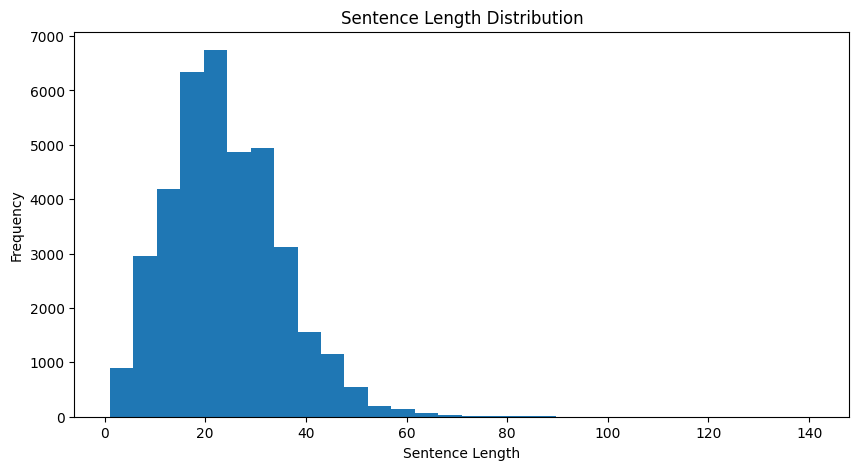

In [10]:
sentence_lengths = [
    len(sentence)
    for sentence in train_sentences
]

plt.figure(figsize=(10,5))

plt.hist(sentence_lengths,
         bins=30)

plt.title("Sentence Length Distribution")
plt.xlabel("Sentence Length")
plt.ylabel("Frequency")

plt.show()

In [11]:
word2idx = {
    "<PAD>":0, # use 0 for  short sentences
    "<UNK>":1 # use 1 for unknown words
}
# create a dictionary to map each unique word in the training dataset to a unique index, starting with special tokens for padding and unknown words
for sentence in train_sentences:

    for word in sentence:
# if word is nor already in the word2idx add it 
        if word not in word2idx:
            word2idx[word] = len(word2idx)

print("Vocabulary Size:",
      len(word2idx))

Vocabulary Size: 43359


In [12]:
tag2idx = {}
# convet the pos tags into a dictionary that maps each unique tag to a unique index
for sentence_tags in train_tags:

    for tag in sentence_tags:

        if tag not in tag2idx:
            tag2idx[tag] = len(tag2idx)

idx2tag = {
    idx:tag
    for tag, idx in tag2idx.items()
}

print("Number of Tags:",
      len(tag2idx))

Number of Tags: 45


In [13]:
def sentence_to_ids(sentence):

    return [
        word2idx.get(word,
                     word2idx["<UNK>"])
        for word in sentence
    ]

In [14]:
def tags_to_ids(tags):

    return [
        tag2idx[tag]
        for tag in tags
    ]

In [15]:
print(train_sentences[0])

print()

print(sentence_to_ids(
    train_sentences[0]
))

['In', 'an', 'Oct.', '19', 'review', 'of', '``', 'The', 'Misanthrope', "''", 'at', 'Chicago', "'s", 'Goodman', 'Theatre', '(', '``', 'Revitalized', 'Classics', 'Take', 'the', 'Stage', 'in', 'Windy', 'City', ',', "''", 'Leisure', '&', 'Arts', ')', ',', 'the', 'role', 'of', 'Celimene', ',', 'played', 'by', 'Kim', 'Cattrall', ',', 'was', 'mistakenly', 'attributed', 'to', 'Christina', 'Haag', '.']

[2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 8, 18, 19, 20, 21, 22, 23, 24, 25, 26, 11, 27, 28, 29, 30, 26, 21, 31, 7, 32, 26, 33, 34, 35, 36, 26, 37, 38, 39, 40, 41, 42, 43]


In [16]:
def pad_sequences(sequences, max_len, pad_value=0):

    padded = []
# Pad each sequence to the maximum length by truncating or adding the pad_value as needed
    for seq in sequences:

        seq = seq[:max_len]

        seq = seq + [pad_value] * (max_len - len(seq))

        padded.append(seq)

    return padded

In [17]:
max_len = max(
    len(sentence)
    for sentence in train_sentences
)

print("Max Length =", max_len)

Max Length = 141


In [18]:
train_inputs = [
    sentence_to_ids(sentence)
    for sentence in train_sentences
]

dev_inputs = [
    sentence_to_ids(sentence)
    for sentence in dev_sentences
]

In [20]:
train_outputs = [
    tags_to_ids(tags)
    for tags in train_tags
]

dev_outputs = [
    tags_to_ids(tags)
    for tags in dev_tags
]

In [21]:
train_inputs = pad_sequences(
    train_inputs,
    max_len,
    word2idx["<PAD>"]
)

train_outputs = pad_sequences(
    train_outputs,
    max_len,
    0
)

dev_inputs = pad_sequences(
    dev_inputs,
    max_len,
    word2idx["<PAD>"]
)

dev_outputs = pad_sequences(
    dev_outputs,
    max_len,
    0
)

In [22]:
import torch
from torch.utils.data import Dataset

In [23]:
class POSDataset(Dataset):
#   A custom dataset class for POS tagging that inherits from the PyTorch Dataset class. It takes in a list of input sequences and their corresponding labels, and implements the __len__ and __getitem__ methods to allow for easy indexing and batching of the data.
    def __init__(self, inputs, labels):

        self.inputs = inputs
        self.labels = labels

    def __len__(self):

        return len(self.inputs)

    def __getitem__(self, idx):

        return (
            torch.tensor(self.inputs[idx],
                         dtype=torch.long),

            torch.tensor(self.labels[idx],
                         dtype=torch.long)
        )

In [24]:
from torch.utils.data import DataLoader

In [25]:
# Read the training and development datasets into custom POSDataset objects, which can be used to create DataLoader objects
train_dataset = POSDataset(
    train_inputs,
    train_outputs
)

dev_dataset = POSDataset(
    dev_inputs,
    dev_outputs
)

In [26]:
# divide the training and development datasets into batches of 32 samples each, with shuffling enabled for the training dataset to improve generalization
train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True
)

dev_loader = DataLoader(
    dev_dataset,
    batch_size=32,
    shuffle=False
)

In [27]:
print("Train Sentences:",
      len(train_dataset)) # number of sentences in the training dataset

print("Dev Sentences:",
      len(dev_dataset)) # number of sentences in the development dataset (validation dataset)

print("Train Batches:",
      len(train_loader)) # number of batches in the training dataset

print("Dev Batches:",
      len(dev_loader)) # number of batches in the development dataset (validation dataset)

print("Vocabulary Size:",
      len(word2idx)) # number of unique words in the training dataset

print("Number of Tags:",
      len(tag2idx)) # number of unique part-of-speech tags in the training dataset

Train Sentences: 37840
Dev Sentences: 1992
Train Batches: 1183
Dev Batches: 63
Vocabulary Size: 43359
Number of Tags: 45


In [28]:
max_len = max(len(s) for s in train_sentences)

print("Max Length:", max_len)

Max Length: 141


In [38]:
def pad_sequences(sequences, max_len, pad_value=0):

    padded = []

    for seq in sequences:
        seq = seq[:max_len]
        seq = seq + [pad_value] * (max_len - len(seq))
        padded.append(seq)

    return padded


train_inputs = pad_sequences(train_inputs, max_len, word2idx["<PAD>"])
dev_inputs   = pad_sequences(dev_inputs, max_len, word2idx["<PAD>"])

train_outputs = pad_sequences(train_outputs, max_len, 0)
dev_outputs   = pad_sequences(dev_outputs, max_len, 0)

In [39]:
train_inputs = [sentence_to_ids(s) for s in train_sentences]
dev_inputs   = [sentence_to_ids(s) for s in dev_sentences]

In [40]:
train_outputs = [tags_to_ids(t) for t in train_tags]
dev_outputs   = [tags_to_ids(t) for t in dev_tags]

In [42]:
train_inputs = pad_sequences(train_inputs, max_len, word2idx["<PAD>"])
dev_inputs   = pad_sequences(dev_inputs, max_len, word2idx["<PAD>"])

train_outputs = pad_sequences(train_outputs, max_len, 0)
dev_outputs   = pad_sequences(dev_outputs, max_len, 0)

In [43]:
import torch
from torch.utils.data import Dataset, DataLoader

class POSDataset(Dataset):
    def __init__(self, inputs, labels):
        self.inputs = inputs
        self.labels = labels

    def __len__(self):
        return len(self.inputs)

    def __getitem__(self, idx):
        return (
            torch.tensor(self.inputs[idx], dtype=torch.long),
            torch.tensor(self.labels[idx], dtype=torch.long)
        )


train_dataset = POSDataset(train_inputs, train_outputs)
dev_dataset   = POSDataset(dev_inputs, dev_outputs)

In [44]:
print(len(train_dataset))
print(len(dev_dataset))
print(len(train_loader))
print(len(dev_loader))

print(len(word2idx))
print(len(tag2idx))
print(max_len)

37840
1992
1183
63
43359
45
141


In [45]:
import torch.nn as nn

class BiLSTMTagger(nn.Module):

    def __init__(self, vocab_size, tag_size, embedding_dim=128, hidden_dim=128):

        super().__init__()

        self.embedding = nn.Embedding(
            vocab_size,
            embedding_dim,
            padding_idx=0
        )

        self.lstm = nn.LSTM(
            embedding_dim,
            hidden_dim,
            bidirectional=True,
            batch_first=True
        )

        self.fc = nn.Linear(hidden_dim * 2, tag_size)

    def forward(self, x):
        x = self.embedding(x)
        lstm_out, _ = self.lstm(x)
        logits = self.fc(lstm_out)
        return logits

In [46]:
import torch.optim as optim

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = BiLSTMTagger(len(word2idx), len(tag2idx)).to(device)

criterion = nn.CrossEntropyLoss(ignore_index=0)
optimizer = optim.Adam(model.parameters(), lr=0.001)

In [47]:
for epoch in range(5):

    model.train()
    total_loss = 0

    for x, y in train_loader:

        x = x.to(device)
        y = y.to(device)

        optimizer.zero_grad()

        output = model(x)

        output = output.view(-1, output.shape[-1])
        y = y.view(-1)

        loss = criterion(output, y)

        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    print(f"Epoch {epoch+1}, Loss: {total_loss:.4f}")

Epoch 1, Loss: 750.7312
Epoch 2, Loss: 253.3032
Epoch 3, Loss: 156.2430
Epoch 4, Loss: 104.9560
Epoch 5, Loss: 72.5653


In [ ]:
correct = 0
total = 0

with torch.no_grad():

    for x, y in dev_loader:

        output = model(x)

        preds = output.argmax(dim=-1)

        preds = preds.view(-1)
        y = y.view(-1)

        mask = y != 0   

        correct += (preds[mask] == y[mask]).sum().item()
        total += mask.sum().item()

accuracy = correct / total

print("BiLSTM Accuracy:", accuracy)

BiLSTM Accuracy: 0.9551449292706863


In [49]:
def accuracy(preds, labels):

    correct = (preds == labels).sum().item()
    total = labels.numel()

    return correct / total

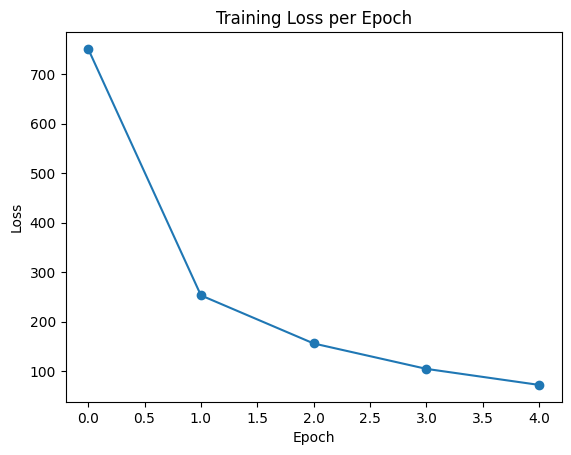

In [50]:
losses = [750.7312, 253.3032, 156.2430, 104.9560, 72.5653]
import matplotlib.pyplot as plt

plt.plot(losses, marker='o')
plt.title("Training Loss per Epoch")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.show()

In [51]:
from collections import defaultdict, Counter

word_tag_counts = defaultdict(Counter)
# count the occurrences of each word-tag pair in the training dataset and store them in a nested dictionary, where the outer dictionary maps each word to a Counter object that counts the occurrences of each tag associated with that word
for sentence, tags in zip(train_sentences, train_tags):
    for w, t in zip(sentence, tags):
        word_tag_counts[w][t] += 1

In [52]:
word_most_freq_tag = {}
# determine the most frequent tag for each word in the training dataset by iterating through the word_tag_counts dictionary and selecting the tag with the highest count for each word, storing the results in a new dictionary called word_most_freq_tag
for word, counter in word_tag_counts.items():
    word_most_freq_tag[word] = counter.most_common(1)[0][0]

In [53]:
all_tags = [tag for tags in train_tags for tag in tags]
# compute the common tag in the training dataset
most_common_tag = Counter(all_tags).most_common(1)[0][0]

print("Most common tag:", most_common_tag)

Most common tag: NOUN-NN


In [54]:
def baseline_predict(sentence):
# this no ai model, it just predict the most common tag for each word in the sentence, if the word is not in the training dataset it will predict the most common tag in the training dataset
    preds = []

    for word in sentence:

        if word in word_most_freq_tag:
            preds.append(word_most_freq_tag[word])
        else:
            preds.append(most_common_tag)

    return preds

In [55]:
def evaluate_baseline(sentences, gold_tags):

    correct = 0
    total = 0

    for sentence, true_tags in zip(sentences, gold_tags):

        pred_tags = baseline_predict(sentence)

        for p, t in zip(pred_tags, true_tags):
            if p == t:
                correct += 1
            total += 1

    accuracy = correct / total
    return accuracy

In [56]:
baseline_acc = evaluate_baseline(dev_sentences, dev_tags)

print("Baseline Accuracy:", baseline_acc)

Baseline Accuracy: 0.9141238382209396
